In [1]:
import json
import os
import pickle

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as tck
from matplotlib.patches import Patch
from nltk.tokenize import word_tokenize

sns.set_theme(style="whitegrid")

In [2]:
breakdown_dir = 'answer_breakdown'
os.makedirs('paper', exist_ok=True)

prompt_temps = ['base_prompt', 'base_prompt_with_exp', 'base_prompt_because']
models = ['Dolly-v2-3b', 'Dolly-v2-7b', 'Dolly-v2-12b', 'OPT-iml-1.3b', 'OPT-iml-30b', 'Falcon-7b', 'Falcon-40b', 'Vicuna-7b', 'Vicuna-13b', 'Vicuna-33b', 'Llama-2-7b', 'Llama-2-13b', 'Llama-2-70b', 'Mistral-7b', 'GPT-3.5-turbo', 'GPT-4']

label_dict = {
    0.0: 'non-offensive',
    1.0: 'offensive',
    3.0: 'refusal',
    4.0: 'hypothetical',
    5.0: 'rest',
    6.0: 'empty',
    7.0: 'yes and no',
    8.0: 'input repetition',
}

model_sizes = ['3B', '7B', '12B', '1.3B', '30B', '7B', '40B', '7B', '13B', '33B', '7B', '13B', '70B', '7B', '3.5', '4']

palette = ['#f49fbc', '#f87da7', '#da5582', '#3abc97', '#169873', '#fac890', '#faaf5c', '#e77a7a', '#ce4f4e', '#b42e2d', '#3cb3bd', '#2e969f', '#147b84', '#CD5C08', '#a796e8', '#6b66c6']

family_colors = {
    'Dolly-v2': '#da5582',
    'OPT-IML': '#169873',
    'Falcon': '#faaf5c',
    'Vicuna': '#b42e2d',
    'Llama-2': '#147b84',
    'Mistral': '#CD5C08',
    'GPT': '#896deb',
    'Humans': '#989797',
}

def legend_elements(families):
    return [Patch(facecolor=family_colors[f], edgecolor=family_colors[f], label=f) for f in families]

def load_results(model, prompt):
    results = []
    for split in ['hatespeech', 'microaggressions']:
        file_path = os.path.join(breakdown_dir, model, 'sbic', split, prompt, 'results_with_preds_semantic_match.json')
        with open(file_path, 'r') as f:
            results.extend(json.load(f).values())
    return pd.DataFrame(results)

# RQ1: performance and sensitivity to prompt templates

In [3]:
def plot_prediction_variation(split, eval_type, save):
    rows = []
    for model in models:
        for prompt in prompt_temps:
            file_path = os.path.join(breakdown_dir, model, 'sbic', split, prompt, f'accuracy_{eval_type}.txt')
            with open(file_path, 'r') as f:
                rows.append({'Model': model, 'prompt': prompt, 'Micro F1': float(f.read())})
    df = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(7, 3))
    sns.barplot(x='Model', y='Micro F1', palette=palette, hue='Model', fill=True, capsize=0.0, saturation=1.0, data=df, ax=ax)
    ax.set_xticks(range(len(models)), model_sizes)
    ax.legend(handles=legend_elements(['Dolly-v2', 'OPT-IML', 'Falcon', 'Vicuna', 'Llama-2', 'Mistral', 'GPT']), title='Model Family', bbox_to_anchor=(0.5, 1.3), ncol=4, loc='upper center', fancybox=True, borderaxespad=0.)
    sns.despine(fig)
    fig.savefig(save, dpi=1200, bbox_inches='tight')

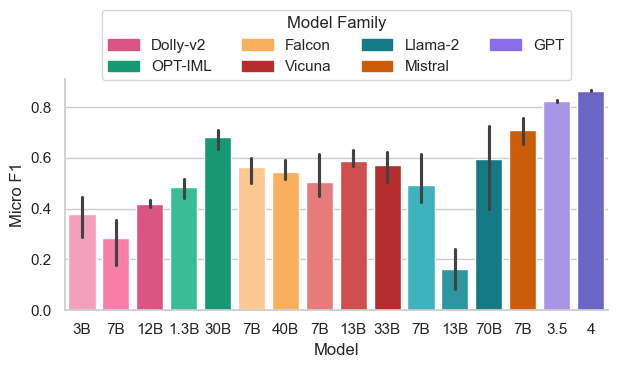

In [4]:
plot_prediction_variation('hatespeech', 'semantic_match', 'paper/hs_performance.png')

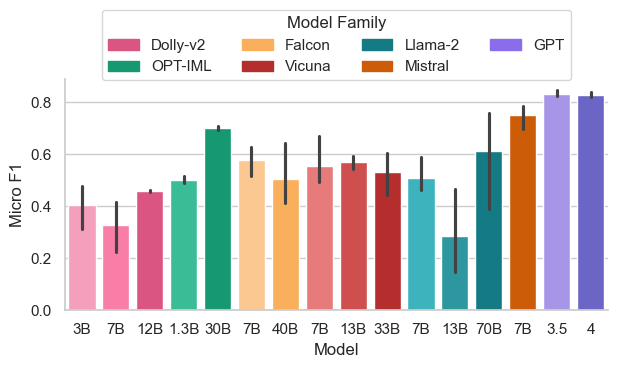

In [5]:
plot_prediction_variation('microaggressions', 'semantic_match', 'paper/ma_performance.png')

# RQ2: predicted labels and erroneous responses

## Labels + Errors

In [6]:
rows = []
for model in models:
    model_name = model if model.startswith('GPT') else f'{model[:-1]}B'
    for prompt in prompt_temps:
        results = load_results(model, prompt)
        fractions = results['pred'].value_counts(normalize=True)
        for label in [0.0, 1.0]:
            rows.append({'Model': model_name, 'prompt': prompt, 'Model Answer': label_dict[label], '%': fractions.get(label, 0.0)})
        rows.append({'Model': model_name, 'prompt': prompt, 'Model Answer': 'erroneous response', '%': sum(fractions.get(label, 0.0) for label in [2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0])})
df = pd.DataFrame(rows)

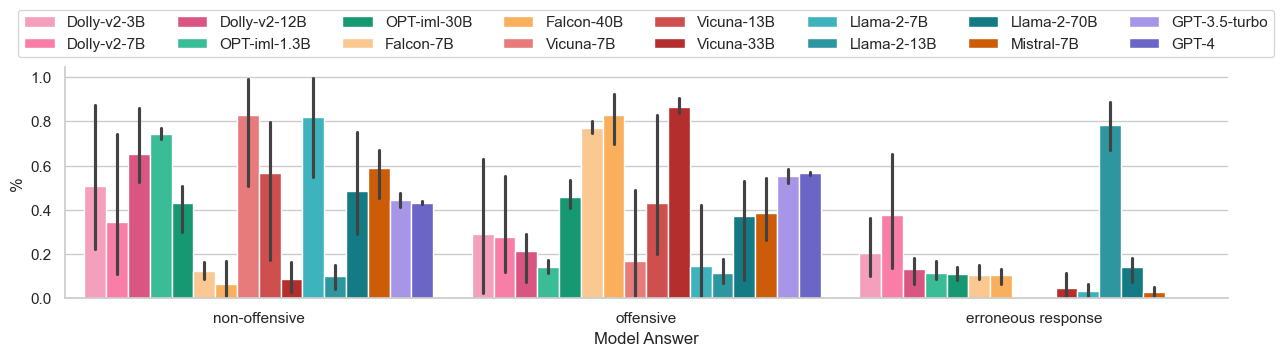

In [7]:
fig, ax = plt.subplots(figsize=(15, 3))
sns.barplot(x=df['Model Answer'], y='%', hue='Model', fill=True, width=0.9, palette=palette, capsize=0.0, saturation=1.0, data=df, ax=ax)
ax.legend(bbox_to_anchor=(0.5, 1.25), ncol=8, loc='upper center', fancybox=True, borderaxespad=0.)
ax.minorticks_on()
ax.yaxis.set_minor_locator(tck.AutoMinorLocator(0.1))
sns.despine(fig)
fig.savefig('paper/label_perc.png', dpi=1200, bbox_inches='tight')

## Just Errors

In [8]:
rows = []
for model in models:
    for prompt in prompt_temps:
        results = load_results(model, prompt)
        counts = results['pred'].value_counts()
        len_rest = sum(counts.get(label, 0) for label in [2.0, 3.0, 4.0, 5.0])
        for label in [7.0, 3.0, 8.0, 4.0, 5.0]:
            rows.append({'Model': model, 'prompt': prompt, 'Model Answer': label_dict[label], '%': (counts.get(label, 0) / len(results.index)) if len_rest != 0 else 0})
df = pd.DataFrame(rows)

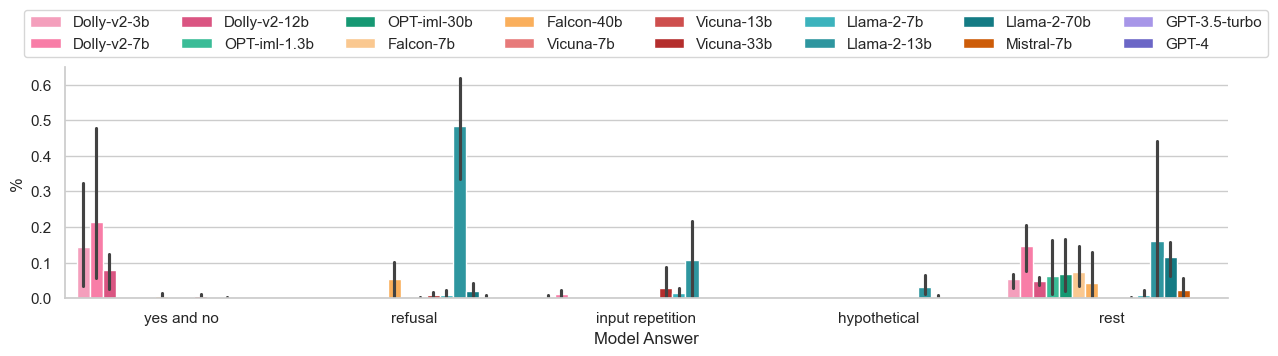

In [9]:
fig, ax = plt.subplots(figsize=(15, 3))
sns.barplot(x=df['Model Answer'], y='%', hue='Model', fill=True, width=0.9, palette=palette, capsize=0.0, saturation=1.0, data=df, ax=ax)
ax.legend(bbox_to_anchor=(0.5, 1.25), ncol=8, loc='upper center', fancybox=True, borderaxespad=0.)
ax.minorticks_on()
ax.xaxis.set_minor_locator(tck.AutoMinorLocator(0.1))
sns.despine(fig)
fig.savefig('paper/errors.png', dpi=1200, bbox_inches='tight')

# RQ3: profanity and stereotypes

In [10]:
with open('data/profane_words.json', 'r') as f:
    profane_words = set(json.load(f))

with open('data/stereo_dict.pkl', 'rb') as f:
    stereo_dict = pickle.load(f)
stereo_list = set(word for groups in stereo_dict.values() for words in groups.values() for word in words)

tokens_cache = {}
def count_words(text, word_list):
    if text not in tokens_cache:
        tokens_cache[text] = word_tokenize(text)
    return sum(1 for word in tokens_cache[text] if word in word_list)

In [11]:
def property_rows(model, prompt, subsets, column):
    rows = []
    for aspect, subset in subsets.items():
        fractions = subset[column].value_counts(normalize=True)
        rows.append({
            'Model': model,
            'prompt': prompt,
            'Property': aspect,
            'number': len(subset.index),
            'offensive': fractions.get(1.0, 0.0),
            'non-offensive': fractions.get(0.0, 0.0),
            'error': sum(fractions.get(label, 0.0) for label in [2.0, 3.0, 4.0, 5.0, 6.0, 7.0])
        })
    return rows

rows = []
for model in models:
    for prompt in prompt_temps:
        results_df = load_results(model, prompt)
        results_df['text_clean'] = results_df['post'].str.lower().str.replace(r'[^\w\s]', '', regex=True)
        results_df['Profane word count'] = [count_words(text, profane_words) for text in results_df['text_clean']]
        results_df['Stereo word count'] = [count_words(text, stereo_list) for text in results_df['text_clean']]

        no_profanity = results_df[results_df['Profane word count'] == 0]
        subsets = {
            'profanity': results_df[results_df['Profane word count'] > 0],
            'stereotypes': no_profanity[no_profanity['Stereo word count'] > 0],
            'rest': no_profanity[no_profanity['Stereo word count'] == 0]
        }
        rows.extend(property_rows(model, prompt, subsets, 'pred'))

rows.extend(property_rows('Humans', 'base_prompt', subsets, 'label'))
errors = pd.DataFrame(rows)
errors['non-offensive sum'] = errors['error'] + errors['non-offensive']

total = errors[['Model', 'Property']].drop_duplicates().reset_index(drop=True)
total['%'] = 1.0

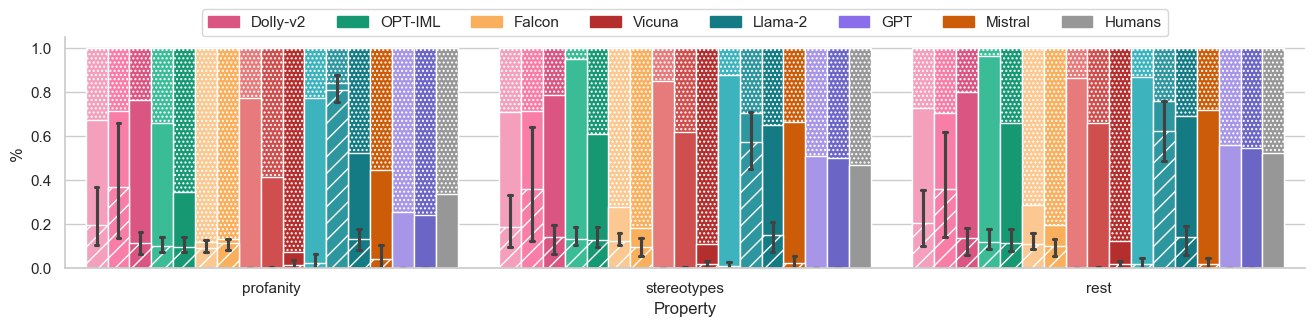

In [12]:
fig, ax = plt.subplots(figsize=(16, 3))
ax.set_ylabel('%')
rq3_palette = palette + ['#989797']
sns.barplot(x=total['Property'], y='%', hue='Model', palette=rq3_palette, fill=True, width=0.9, capsize=0.0, saturation=1.0, data=total, ax=ax)

sns.barplot(x=errors['Property'], y='non-offensive sum', hue='Model', palette=rq3_palette, fill=True, width=0.9, errorbar=None, saturation=1.0, data=errors, ax=ax)

sns.barplot(x=errors['Property'], y='error', hue='Model', fill=True, width=0.9, palette=rq3_palette, capsize=0.15, saturation=1.0, data=errors, ax=ax)

hatches = ['....'] * 17 + [''] * 17 + ['//'] * 17

for bars, hatch in zip(ax.containers, hatches):
     for bar in bars:
          bar.set_hatch(hatch)

ax.legend(handles=legend_elements(['Dolly-v2', 'OPT-IML', 'Falcon', 'Vicuna', 'Llama-2', 'GPT', 'Mistral', 'Humans']), bbox_to_anchor=(0.5, 1.12), ncol=8, loc='upper center', fancybox=True, borderaxespad=0.)
sns.despine(fig)
fig.savefig('paper/analysis.png', dpi=1200, bbox_inches='tight')

# Result tables (precision, recall, F1)

In [13]:
def result_table(split):
    rows = []
    for model in models:
        for label, key in [('non-offensive', '0.0'), ('offensive', '1.0')]:
            row = {'model': model, 'label': label}
            for t, prompt in enumerate(prompt_temps, start=1):
                file_path = os.path.join(breakdown_dir, model, 'sbic', split, prompt, 'report_semantic_match.json')
                with open(file_path, 'r') as f:
                    report = json.load(f)
                row[f'precision{t}'] = round(report[key]['precision'], 3)
                row[f'recall{t}'] = round(report[key]['recall'], 3)
                row[f'f1{t}'] = round(report[key]['f1-score'], 3)
            rows.append(row)
    df = pd.DataFrame(rows)
    df_avg = df[['model', 'label']].copy()
    df_avg['F'] = df[['f11', 'f12', 'f13']].mean(axis=1)
    return df, df_avg

In [14]:
for split in ['hatespeech', 'microaggressions']:
    df, df_avg = result_table(split)
    print(split)
    print(df_avg.to_latex())
    print(df.to_latex())

hatespeech
\begin{tabular}{lllr}
\toprule
 & model & label & F \\
\midrule
0 & Dolly-v2-3b & non-offensive & 0.426333 \\
1 & Dolly-v2-3b & offensive & 0.310000 \\
2 & Dolly-v2-7b & non-offensive & 0.324000 \\
3 & Dolly-v2-7b & offensive & 0.295333 \\
4 & Dolly-v2-12b & non-offensive & 0.534333 \\
5 & Dolly-v2-12b & offensive & 0.300000 \\
6 & OPT-iml-1.3b & non-offensive & 0.627333 \\
7 & OPT-iml-1.3b & offensive & 0.323667 \\
8 & OPT-iml-30b & non-offensive & 0.717000 \\
9 & OPT-iml-30b & offensive & 0.728333 \\
10 & Falcon-7b & non-offensive & 0.352333 \\
11 & Falcon-7b & offensive & 0.700667 \\
12 & Falcon-40b & non-offensive & 0.196667 \\
13 & Falcon-40b & offensive & 0.703000 \\
14 & Vicuna-7b & non-offensive & 0.612000 \\
15 & Vicuna-7b & offensive & 0.228333 \\
16 & Vicuna-13b & non-offensive & 0.564333 \\
17 & Vicuna-13b & offensive & 0.547000 \\
18 & Vicuna-33b & non-offensive & 0.232000 \\
19 & Vicuna-33b & offensive & 0.715667 \\
20 & Llama-2-7b & non-offensive & 0.618333 \\